In [ ]:
!pip install lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=1cec3f80e8efd2042b92bf60b1a81694f6da37a7b4c708ca3861ae98d70f0892
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lifelines]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
transactions = pd.read_csv('/content/cleaned_transactions.csv')

transactions['InvoiceDate'] = pd.to_datetime(
    transactions['InvoiceDate']
)

print("Dataset shape:", transactions.shape)

transactions.head()

Dataset shape: (1033036, 10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,IsNegativeQuantity
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False


In [ ]:
print("Columns:")
print(transactions.columns.tolist())

print("\nMissing Customer IDs:")
print(transactions['CustomerID'].isnull().sum())

print("\nDate range:")
print("First transaction:", transactions['InvoiceDate'].min())
print("Last transaction:", transactions['InvoiceDate'].max())

print("\nUnique customers:")
print(transactions['CustomerID'].nunique())

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancellation', 'IsNegativeQuantity']

Missing Customer IDs:
235151

Date range:
First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00

Unique customers:
5942


In [ ]:
# End of available observation period
dataset_end = transactions['InvoiceDate'].max()

# Aggregate transactions at customer level
customer_survival = (
    transactions
    .groupby('CustomerID')
    .agg(
        FirstPurchase=('InvoiceDate', 'min'),
        LastPurchase=('InvoiceDate', 'max'),
        TotalOrders=('InvoiceDate', 'nunique')
    )
    .reset_index()
)

# Calculate the date when 90-day inactivity is reached
customer_survival['ChurnDate'] = (
    customer_survival['LastPurchase']
    + pd.Timedelta(days=90)
)

# Event = 1 if 90 days of inactivity are observable
customer_survival['Event'] = (
    customer_survival['ChurnDate'] <= dataset_end
).astype(int)

# Determine the end of each customer's observation
customer_survival['ObservationEnd'] = np.where(
    customer_survival['Event'] == 1,
    customer_survival['ChurnDate'],
    dataset_end
)

customer_survival['ObservationEnd'] = pd.to_datetime(
    customer_survival['ObservationEnd']
)

# Calculate duration in days
customer_survival['Duration'] = (
    customer_survival['ObservationEnd']
    - customer_survival['FirstPurchase']
).dt.days

print("Survival dataset created!")
customer_survival.head()

Survival dataset created!


,CustomerID,FirstPurchase,LastPurchase,TotalOrders,ChurnDate,Event,ObservationEnd,Duration
0,12346.0,2009-12-14 08:34:00,2011-01-18 10:17:00,17,2011-04-18 10:17:00,1,2011-04-18 10:17:00,490
1,12347.0,2010-10-31 14:20:00,2011-12-07 15:52:00,8,2012-03-06 15:52:00,0,2011-12-09 12:50:00,403
2,12348.0,2010-09-27 14:59:00,2011-09-25 13:13:00,5,2011-12-24 13:13:00,0,2011-12-09 12:50:00,437
3,12349.0,2009-12-04 12:49:00,2011-11-21 09:51:00,5,2012-02-19 09:51:00,0,2011-12-09 12:50:00,735
4,12350.0,2011-02-02 16:01:00,2011-02-02 16:01:00,1,2011-05-03 16:01:00,1,2011-05-03 16:01:00,90


In [ ]:
print("Survival Dataset Shape:", customer_survival.shape)

print("\nEvent Distribution:")
print(customer_survival['Event'].value_counts())

print("\nEvent Percentages:")
print(
    customer_survival['Event']
    .value_counts(normalize=True) * 100
)

print("\nDuration Statistics:")
print(customer_survival['Duration'].describe())

print("\nMissing Values:")
print(customer_survival.isnull().sum())

Survival Dataset Shape: (5942, 8)

Event Distribution:
Event
1    3024
0    2918
Name: count, dtype: int64

Event Percentages:
Event
1    50.891956
0    49.108044
Name: proportion, dtype: float64

Duration Statistics:
count    5942.000000
mean      336.124537
std       245.417547
min         0.000000
25%        90.000000
50%       288.000000
75%       570.000000
max       738.000000
Name: Duration, dtype: float64

Missing Values:
CustomerID        0
FirstPurchase     0
LastPurchase      0
TotalOrders       0
ChurnDate         0
Event             0
ObservationEnd    0
Duration          0
dtype: int64


In [ ]:
customer_survival.to_csv(
    'customer_survival_dataset.csv',
    index=False
)

from google.colab import files

files.download('customer_survival_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Keep genuine completed purchases
sales = transactions.copy()

# Remove missing customer IDs
sales = sales.dropna(subset=['CustomerID'])

# Exclude cancelled invoices
sales = sales[
    ~sales['IsCancellation'].astype(str).str.lower().isin(
        ['true', '1', 'yes']
    )
]

# Exclude returns and non-positive transactions
sales = sales[
    (sales['Quantity'] > 0) &
    (sales['UnitPrice'] > 0)
]

# Ensure dates are datetime
sales['InvoiceDate'] = pd.to_datetime(
    sales['InvoiceDate']
)

print("Valid purchase records:", sales.shape)
print("Unique customers:", sales['CustomerID'].nunique())

Valid purchase records: (779425, 10)
Unique customers: 5878


In [ ]:
dataset_end = transactions['InvoiceDate'].max()

survival_records = []

for customer_id, group in sales.groupby('CustomerID'):

    # Get distinct purchase dates
    purchase_dates = sorted(
        group['InvoiceDate'].drop_duplicates()
    )

    first_purchase = purchase_dates[0]

    event = 0
    observation_end = dataset_end

    # Check gaps between consecutive purchases
    for i in range(len(purchase_dates) - 1):

        gap = (
            purchase_dates[i + 1] - purchase_dates[i]
        ).days

        if gap >= 90:

            event = 1

            observation_end = (
                purchase_dates[i] +
                pd.Timedelta(days=90)
            )

            break

    # Check the final period up to dataset end
    if event == 0:

        final_gap = (
            dataset_end - purchase_dates[-1]
        ).days

        if final_gap >= 90:

            event = 1

            observation_end = (
                purchase_dates[-1] +
                pd.Timedelta(days=90)
            )

    # Calculate duration
    duration = (
        observation_end - first_purchase
    ).days

    survival_records.append({

        'CustomerID': customer_id,

        'FirstPurchase': first_purchase,

        'LastPurchase': purchase_dates[-1],

        'TotalOrders': group['Invoice'].nunique(),

        'Event': event,

        'ObservationEnd': observation_end,

        'Duration': duration

    })


customer_survival = pd.DataFrame(survival_records)

print("Corrected survival dataset created!")
customer_survival.head()

Corrected survival dataset created!


,CustomerID,FirstPurchase,LastPurchase,TotalOrders,Event,ObservationEnd,Duration
0,12346.0,2009-12-14 08:34:00,2011-01-18 10:01:00,12,1,2010-05-31 13:08:00,168
1,12347.0,2010-10-31 14:20:00,2011-12-07 15:52:00,8,1,2011-10-31 08:48:00,364
2,12348.0,2010-09-27 14:59:00,2011-09-25 13:13:00,5,1,2011-07-04 10:47:00,279
3,12349.0,2010-04-29 13:20:00,2011-11-21 09:51:00,4,1,2010-08-16 09:57:00,108
4,12350.0,2011-02-02 16:01:00,2011-02-02 16:01:00,1,1,2011-05-03 16:01:00,90


In [ ]:
print("Survival Dataset Shape:",
      customer_survival.shape)

print("\nEvent Distribution:")

print(
    customer_survival['Event'].value_counts()
)

print("\nEvent Percentages:")

print(
    customer_survival['Event']
    .value_counts(normalize=True) * 100
)

print("\nDuration Statistics:")

print(
    customer_survival['Duration'].describe()
)

print("\nMissing Values:")

print(
    customer_survival.isnull().sum()
)

Survival Dataset Shape: (5878, 7)

Event Distribution:
Event
1    4843
0    1035
Name: count, dtype: int64

Event Percentages:
Event
1    82.39197
0    17.60803
Name: proportion, dtype: float64

Duration Statistics:
count    5878.000000
mean      149.375128
std       138.455102
min         0.000000
25%        90.000000
50%        90.000000
75%       153.000000
max       738.000000
Name: Duration, dtype: float64

Missing Values:
CustomerID        0
FirstPurchase     0
LastPurchase      0
TotalOrders       0
Event             0
ObservationEnd    0
Duration          0
dtype: int64


In [ ]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

In [ ]:
kmf = KaplanMeierFitter()

kmf.fit(
    durations=customer_survival['Duration'],
    event_observed=customer_survival['Event'],
    label='Customer Survival Probability'
)

print("Kaplan-Meier model fitted successfully!")

Kaplan-Meier model fitted successfully!


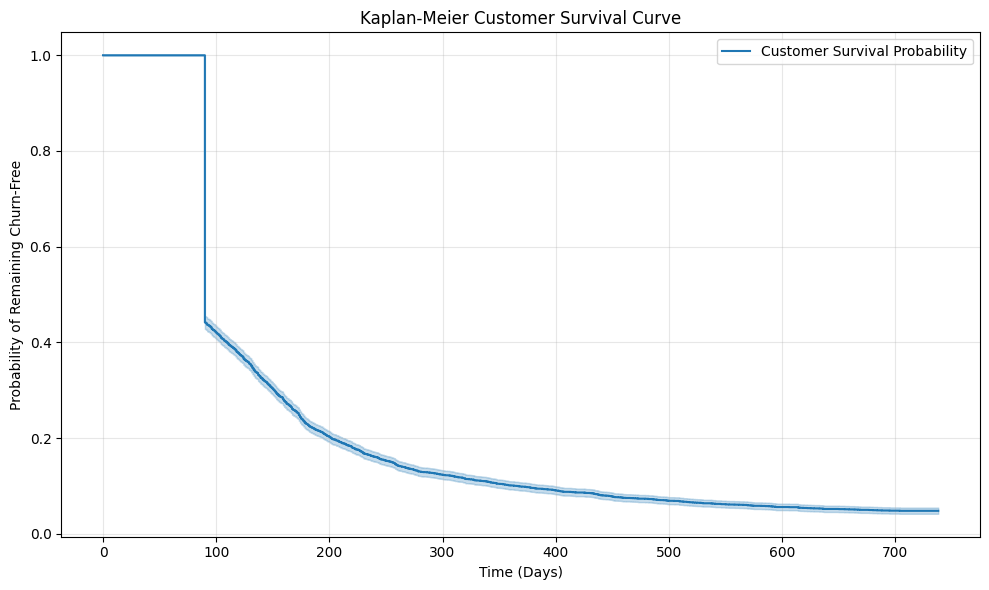

In [ ]:
plt.figure(figsize=(10, 6))

kmf.plot_survival_function(
    ci_show=True
)

plt.title(
    'Kaplan-Meier Customer Survival Curve'
)

plt.xlabel('Time (Days)')

plt.ylabel('Probability of Remaining Churn-Free')

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
survival_times = [30, 60, 90, 180, 270, 365, 540, 720]

survival_probabilities = kmf.survival_function_at_times(
    survival_times
)

print("Customer Survival Probabilities:")

print(survival_probabilities)

Customer Survival Probabilities:
30     1.000000
60     1.000000
90     0.441394
180    0.229163
270    0.136106
365    0.099879
540    0.062835
720    0.047807
Name: Customer Survival Probability, dtype: float64


In [ ]:
print(
    "Median Survival Time:",
    kmf.median_survival_time_,
    "days"
)

Median Survival Time: 90.0 days


In [ ]:
customer_survival.to_csv(
    'customer_survival_dataset.csv',
    index=False
)

from google.colab import files

files.download('customer_survival_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Median Survival Time:")
print(kmf.median_survival_time_)

print("\nSurvival Function:")
display(kmf.survival_function_.head(15))

print("\nConfidence Intervals:")
display(kmf.confidence_interval_.head(10))

Median Survival Time:
90.0

Survival Function:


,Customer Survival Probability
timeline,
0.0,1.0
1.0,1.0
2.0,1.0
3.0,1.0
4.0,1.0
5.0,1.0
6.0,1.0
7.0,1.0
8.0,1.0



Confidence Intervals:


,Customer Survival Probability_lower_0.95,Customer Survival Probability_upper_0.95
0.0,1.0,1.0
1.0,1.0,1.0
2.0,1.0,1.0
3.0,1.0,1.0
4.0,1.0,1.0
5.0,1.0,1.0
6.0,1.0,1.0
7.0,1.0,1.0
8.0,1.0,1.0
9.0,1.0,1.0


In [ ]:
cox_records = []

for customer_id, group in sales.groupby('CustomerID'):

    group = group.sort_values('InvoiceDate')

    purchase_dates = sorted(
        group['InvoiceDate'].drop_duplicates()
    )

    first_purchase = purchase_dates[0]

    # Set landmark at 90 days after first purchase
    landmark_date = first_purchase + pd.Timedelta(days=90)

    # Exclude customers without 90 days of initial observation
    if landmark_date > dataset_end:
        continue

    # Identify the first 90-day inactivity event
    first_event_date = None

    for i in range(len(purchase_dates) - 1):

        if (
            purchase_dates[i + 1] - purchase_dates[i]
        ).days >= 90:

            first_event_date = (
                purchase_dates[i] +
                pd.Timedelta(days=90)
            )

            break

    # Check inactivity after the final purchase
    if first_event_date is None:

        possible_event = (
            purchase_dates[-1] +
            pd.Timedelta(days=90)
        )

        # Exclude observations with no positive follow-up time
        if duration <= 0:
            continue

        if possible_event <= dataset_end:
            first_event_date = possible_event

    # Exclude customers who experienced the event
    # on or before the 90-day landmark
    if (
        first_event_date is not None
        and first_event_date <= landmark_date
    ):
        continue

    # Features must only use the first 90 days
    initial_period = group[
        (group['InvoiceDate'] >= first_purchase) &
        (group['InvoiceDate'] <= landmark_date)
    ].copy()

    # Calculate observation outcome after landmark
    if (
        first_event_date is not None
        and first_event_date <= dataset_end
    ):

        event = 1
        observation_end = first_event_date

    else:

        event = 0
        observation_end = dataset_end

    duration = (
        observation_end - landmark_date
    ).total_seconds() / (24 * 60 * 60)

    # Invoice-level spending
    invoice_revenue = (
        initial_period
        .groupby('Invoice')['Quantity']
        .sum()
    )

    monetary = (
        initial_period['Quantity'] *
        initial_period['UnitPrice']
    ).sum()

    frequency = initial_period['Invoice'].nunique()

    unique_products = initial_period['StockCode'].nunique()

    total_quantity = initial_period['Quantity'].sum()

    active_days = (
        initial_period['InvoiceDate']
        .dt.date.nunique()
    )

    average_order_value = (
        monetary / frequency if frequency > 0 else 0
    )

    cox_records.append({

        'CustomerID': customer_id,

        'Duration': duration,

        'Event': event,

        'Monetary': monetary,

        'Frequency': frequency,

        'UniqueProducts': unique_products,

        'TotalQuantity': total_quantity,

        'ActiveDays': active_days,

        'AverageOrderValue': average_order_value

    })


cox_dataset = pd.DataFrame(cox_records)

print("Cox Dataset Shape:", cox_dataset.shape)

cox_dataset.head()

Cox Dataset Shape: (2491, 9)


,CustomerID,Duration,Event,Monetary,Frequency,UniqueProducts,TotalQuantity,ActiveDays,AverageOrderValue
0,12346.0,78.190278,1,230.55,10,7,51,6,23.055
1,12347.0,274.769444,1,1798.71,3,77,1143,3,599.570
2,12348.0,189.825000,1,1114.96,2,21,1627,2,557.480
3,12349.0,18.859028,1,1268.52,2,47,474,2,634.260
4,12352.0,130.241667,1,343.80,2,18,188,2,171.900


In [ ]:
print("Number of customers:", len(cox_dataset))

print("\nEvent Distribution:")
print(cox_dataset['Event'].value_counts())

print("\nEvent Percentages:")
print(
    cox_dataset['Event']
    .value_counts(normalize=True) * 100
)

print("\nDuration Statistics:")
print(cox_dataset['Duration'].describe())

print("\nMissing Values:")
print(cox_dataset.isnull().sum())

Number of customers: 2491

Event Distribution:
Event
1    2053
0     438
Name: count, dtype: int64

Event Percentages:
Event
1    82.4167
0    17.5833
Name: proportion, dtype: float64

Duration Statistics:
count    2491.000000
mean      150.524159
std       174.651750
min         0.000694
25%        35.960764
50%        83.009722
75%       182.881944
max       648.155556
Name: Duration, dtype: float64

Missing Values:
CustomerID           0
Duration             0
Event                0
Monetary             0
Frequency            0
UniqueProducts       0
TotalQuantity        0
ActiveDays           0
AverageOrderValue    0
dtype: int64


In [ ]:
print("Feature Correlations:")

display(
    cox_dataset[
        [
            'Monetary',
            'Frequency',
            'UniqueProducts',
            'TotalQuantity',
            'ActiveDays',
            'AverageOrderValue'
        ]
    ].corr()
)

Feature Correlations:


,Monetary,Frequency,UniqueProducts,TotalQuantity,ActiveDays,AverageOrderValue
Monetary,1.000000,0.555040,0.345334,0.613231,0.458867,0.620160
Frequency,0.555040,1.000000,0.494063,0.343700,0.898129,0.099413
UniqueProducts,0.345334,0.494063,1.000000,0.179252,0.526496,0.161403
TotalQuantity,0.613231,0.343700,0.179252,1.000000,0.270339,0.417750
ActiveDays,0.458867,0.898129,0.526496,0.270339,1.000000,0.067895
AverageOrderValue,0.620160,0.099413,0.161403,0.417750,0.067895,1.000000


In [ ]:
# Find customers with negative survival duration

negative_duration = cox_dataset[
    cox_dataset['Duration'] < 0
]

print("Number of negative durations:",
      len(negative_duration))

print("\nProblematic customers:")

display(negative_duration.head(20))

Number of negative durations: 0

Problematic customers:


,CustomerID,Duration,Event,Monetary,Frequency,UniqueProducts,TotalQuantity,ActiveDays,AverageOrderValue


In [ ]:
# Inspect the purchase history of problematic customers

negative_ids = negative_duration['CustomerID'].tolist()

for customer_id in negative_ids[:5]:

    group = sales[
        sales['CustomerID'] == customer_id
    ].sort_values('InvoiceDate')

    first_purchase = group['InvoiceDate'].min()

    landmark_date = (
        first_purchase + pd.Timedelta(days=90)
    )

    purchase_dates = sorted(
        group['InvoiceDate'].drop_duplicates()
    )

    print("\nCustomer:", customer_id)
    print("First purchase:", first_purchase)
    print("Landmark date:", landmark_date)
    print("Purchase dates:", purchase_dates[:15])
    print("Recorded duration:",
          negative_duration.loc[
              negative_duration['CustomerID'] == customer_id,
              'Duration'
          ].iloc[0])

In [ ]:
print("Corrected Cox Dataset Shape:", cox_dataset.shape)

print("\nEvent Distribution:")
print(cox_dataset['Event'].value_counts())

print("\nEvent Percentages:")
print(
    cox_dataset['Event']
    .value_counts(normalize=True) * 100
)

print("\nDuration Statistics:")
display(cox_dataset['Duration'].describe())

print("\nNegative Durations:",
      (cox_dataset['Duration'] < 0).sum())

print("\nZero Durations:",
      (cox_dataset['Duration'] == 0).sum())

print("\nMissing Values:")
display(cox_dataset.isnull().sum())

Corrected Cox Dataset Shape: (2491, 9)

Event Distribution:
Event
1    2053
0     438
Name: count, dtype: int64

Event Percentages:
Event
1    82.4167
0    17.5833
Name: proportion, dtype: float64

Duration Statistics:


,Duration
count,2491.000000
mean,150.524159
std,174.651750
min,0.000694
25%,35.960764
50%,83.009722
75%,182.881944
max,648.155556



Negative Durations: 0

Zero Durations: 0

Missing Values:


,0
CustomerID,0
Duration,0
Event,0
Monetary,0
Frequency,0
UniqueProducts,0
TotalQuantity,0
ActiveDays,0
AverageOrderValue,0


In [ ]:
# Identify customers whose first 90-day observation period
# extends beyond the dataset end.

late_customers = []

for customer_id, group in sales.groupby('CustomerID'):

    first_purchase = group['InvoiceDate'].min()

    landmark_date = first_purchase + pd.Timedelta(days=90)

    if landmark_date > dataset_end:
        late_customers.append({
            'CustomerID': customer_id,
            'FirstPurchase': first_purchase,
            'LandmarkDate': landmark_date,
            'DatasetEnd': dataset_end,
            'DaysBeyondDatasetEnd':
                (landmark_date - dataset_end).days
        })

late_customers_df = pd.DataFrame(late_customers)

print("Customers without 90 days of initial observation:",
      len(late_customers_df))

display(late_customers_df.head(20))

Customers without 90 days of initial observation: 597


,CustomerID,FirstPurchase,LandmarkDate,DatasetEnd,DaysBeyondDatasetEnd
0,12367.0,2011-12-05 16:48:00,2012-03-04 16:48:00,2011-12-09 12:50:00,86
1,12390.0,2011-09-21 09:33:00,2011-12-20 09:33:00,2011-12-09 12:50:00,10
2,12398.0,2011-10-25 10:27:00,2012-01-23 10:27:00,2011-12-09 12:50:00,44
3,12420.0,2011-10-07 08:55:00,2012-01-05 08:55:00,2011-12-09 12:50:00,26
4,12430.0,2011-10-27 15:09:00,2012-01-25 15:09:00,2011-12-09 12:50:00,47
5,12442.0,2011-12-06 14:22:00,2012-03-05 14:22:00,2011-12-09 12:50:00,87
6,12446.0,2011-10-13 12:50:00,2012-01-11 12:50:00,2011-12-09 12:50:00,33
7,12448.0,2011-10-26 13:46:00,2012-01-24 13:46:00,2011-12-09 12:50:00,46
8,12452.0,2011-11-23 08:05:00,2012-02-21 08:05:00,2011-12-09 12:50:00,73
9,12478.0,2011-12-06 09:56:00,2012-03-05 09:56:00,2011-12-09 12:50:00,86


In [ ]:
customer_id = 12367

group = sales[sales['CustomerID'] == customer_id]

first_purchase = group['InvoiceDate'].min()
landmark_date = first_purchase + pd.Timedelta(days=90)

print("Customer ID:", customer_id)
print("First Purchase:", first_purchase)
print("Landmark Date:", landmark_date)
print("Dataset End:", dataset_end)
print("Duration from Landmark to Dataset End:",
      (dataset_end - landmark_date).days)

Customer ID: 12367
First Purchase: 2011-12-05 16:48:00
Landmark Date: 2012-03-04 16:48:00
Dataset End: 2011-12-09 12:50:00
Duration from Landmark to Dataset End: -87


In [ ]:
# Inspect zero-duration observations

zero_duration = cox_dataset[
    cox_dataset['Duration'] == 0
].copy()

print("Total zero-duration customers:",
      len(zero_duration))

print("\nEvent distribution among zero-duration customers:")
print(zero_duration['Event'].value_counts())

print("\nEvent percentages:")
print(
    zero_duration['Event'].value_counts(normalize=True) * 100
)

display(zero_duration.head(20))

Total zero-duration customers: 0

Event distribution among zero-duration customers:
Series([], Name: count, dtype: int64)

Event percentages:
Series([], Name: proportion, dtype: float64)


,CustomerID,Duration,Event,Monetary,Frequency,UniqueProducts,TotalQuantity,ActiveDays,AverageOrderValue


In [ ]:
# Inspect zero-duration customers in the corrected Cox dataset

zero_duration = cox_dataset[
    cox_dataset['Duration'] == 0
].copy()

print("Total zero-duration customers:", len(zero_duration))

print("\nEvent distribution:")
print(zero_duration['Event'].value_counts())

print("\nZero-duration customer records:")
display(zero_duration)

Total zero-duration customers: 0

Event distribution:
Series([], Name: count, dtype: int64)

Zero-duration customer records:


,CustomerID,Duration,Event,Monetary,Frequency,UniqueProducts,TotalQuantity,ActiveDays,AverageOrderValue


In [ ]:
print("Cox Dataset Shape:", cox_dataset.shape)

print("\nEvent Distribution:")
print(cox_dataset['Event'].value_counts())

print("\nDuration Statistics:")
display(cox_dataset['Duration'].describe())

print("\nNegative Durations:",
      (cox_dataset['Duration'] < 0).sum())

print("Zero Durations:",
      (cox_dataset['Duration'] <= 0).sum())

print("\nMissing Values:")
display(cox_dataset.isnull().sum())

Cox Dataset Shape: (2491, 9)

Event Distribution:
Event
1    2053
0     438
Name: count, dtype: int64

Duration Statistics:


,Duration
count,2491.000000
mean,150.524159
std,174.651750
min,0.000694
25%,35.960764
50%,83.009722
75%,182.881944
max,648.155556



Negative Durations: 0
Zero Durations: 0

Missing Values:


,0
CustomerID,0
Duration,0
Event,0
Monetary,0
Frequency,0
UniqueProducts,0
TotalQuantity,0
ActiveDays,0
AverageOrderValue,0


In [ ]:
import pandas as pd
import numpy as np

from lifelines import CoxPHFitter
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Select the features for Cox regression

cox_features = [
    'Monetary',
    'Frequency',
    'UniqueProducts',
    'TotalQuantity',
    'AverageOrderValue'
]

cox_model_data = cox_dataset[
    ['Duration', 'Event'] + cox_features
].copy()

# Apply log transformation to reduce skewness

for col in cox_features:
    cox_model_data[col] = np.log1p(cox_model_data[col])

# Standardize the predictor variables

scaler = StandardScaler()

cox_model_data[cox_features] = scaler.fit_transform(
    cox_model_data[cox_features]
)

print("Prepared Cox Model Dataset:")
display(cox_model_data.head())

print("\nDataset Shape:", cox_model_data.shape)

print("\nMissing Values:")
print(cox_model_data.isnull().sum())

Prepared Cox Model Dataset:


,Duration,Event,Monetary,Frequency,UniqueProducts,TotalQuantity,AverageOrderValue
0,78.190278,1,-1.435733,2.941573,-1.739899,-2.068451,-3.527727
1,274.769444,1,0.896678,0.109233,0.783861,0.961286,1.000186
2,189.825000,1,0.353085,-0.696237,-0.618802,1.307109,0.897934
3,18.859028,1,0.499728,-0.696237,0.245802,0.099747,1.079211
4,130.241667,1,-0.982841,-0.696237,-0.781274,-0.803542,-0.752087



Dataset Shape: (2491, 7)

Missing Values:
Duration             0
Event                0
Monetary             0
Frequency            0
UniqueProducts       0
TotalQuantity        0
AverageOrderValue    0
dtype: int64


In [ ]:
# Initialize Cox Proportional Hazards model

cph = CoxPHFitter(penalizer=0.01)

# Fit the model

cph.fit(
    cox_model_data,
    duration_col='Duration',
    event_col='Event',
    show_progress=True
)

# Display model summary

cph.print_summary()

Iteration 1: norm_delta = 5.79e-01, step_size = 0.9500, log_lik = -14463.81662, newton_decrement = 2.35e+02, seconds_since_start = 0.2
Iteration 2: norm_delta = 3.85e-01, step_size = 0.9500, log_lik = -14201.01255, newton_decrement = 2.89e+01, seconds_since_start = 0.4
Iteration 3: norm_delta = 6.73e-02, step_size = 0.9500, log_lik = -14170.16027, newton_decrement = 9.38e-01, seconds_since_start = 0.6
Iteration 4: norm_delta = 1.35e-03, step_size = 1.0000, log_lik = -14169.20767, newton_decrement = 5.52e-04, seconds_since_start = 0.8
Iteration 5: norm_delta = 7.78e-07, step_size = 1.0000, log_lik = -14169.20712, newton_decrement = 1.96e-10, seconds_since_start = 0.9
Convergence success after 5 iterations.


<lifelines.CoxPHFitter: fitted with 2491 total observations, 438 right-censored observations>
             duration col = 'Duration'
                event col = 'Event'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 2491
number of events observed = 2053
   partial log-likelihood = -14169.21
         time fit was run = 2026-11-26 19:43:53 UTC

---
                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                          
Monetary          -0.22      0.80      0.14           -0.50            0.06                0.60                1.06
Frequency         -0.36      0.70      0.08           -0.52           -0.20                0.60                0.81
UniqueProducts    -0.03      0.97      0.03           -0.08            0.03                0.92                1.03
TotalQuantity     -0.15      0.86      0.05           -0.25           -0.06                0.78                0.94
AverageOrderValue  0.10      1.11      0.12           -0.13            0.33                0.88                1.40

                   cmp to     z      p  -log2(p)
covariate                                       
Monetary             0.00 -1.53   0.12      3.00
Frequency            0.00 -4.52 <0.005     17.30
UniqueProducts       0.00 -1.02   0.31      1.71
TotalQuantity        0.00 -3.29 <0.005      9.97
AverageOrderValue    0.00  0.86   0.39      1.36
---
Concordance = 0.67
Partial AIC = 28348.41
log-likelihood ratio test = 589.22 on 5 df
-log2(p) of ll-ratio test = 413.13

In [ ]:
print("Concordance Index:")
print(cph.concordance_index_)

print("\nPartial Log-Likelihood:")
print(cph.log_likelihood_)

print("\nAIC Partial:")
print(cph.AIC_partial_)

Concordance Index:
0.6733362159188565

Partial Log-Likelihood:
-14169.207116480977

AIC Partial:
28348.414232961954


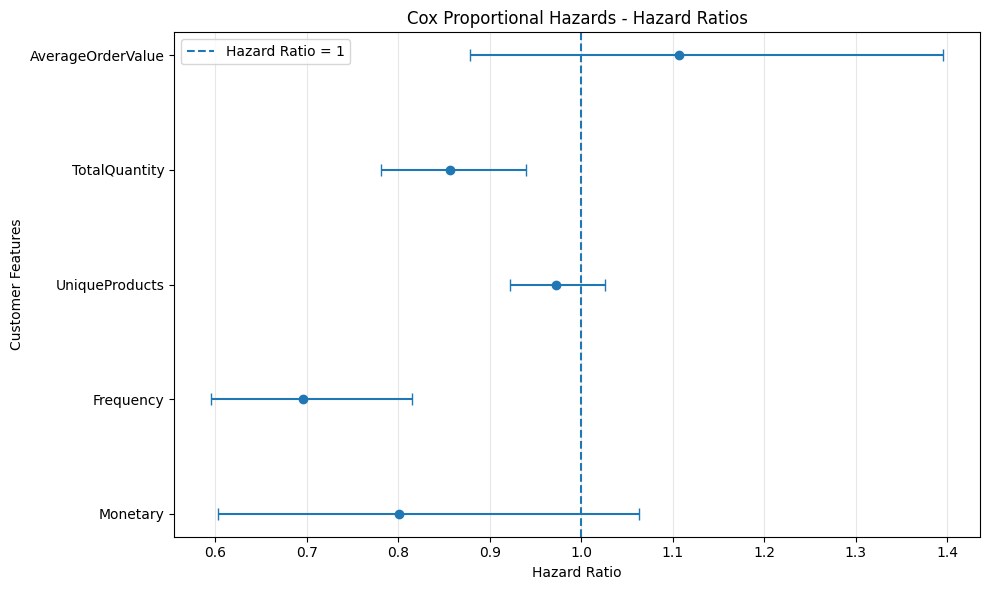

In [ ]:
# Extract hazard ratios and confidence intervals

summary = cph.summary.copy()

plot_data = summary[
    [
        'exp(coef)',
        'exp(coef) lower 95%',
        'exp(coef) upper 95%'
    ]
]

plt.figure(figsize=(10, 6))

y_positions = np.arange(len(plot_data))

plt.errorbar(
    plot_data['exp(coef)'],
    y_positions,
    xerr=[
        plot_data['exp(coef)'] - plot_data['exp(coef) lower 95%'],
        plot_data['exp(coef) upper 95%'] - plot_data['exp(coef)']
    ],
    fmt='o',
    capsize=4
)

plt.axvline(
    x=1,
    linestyle='--',
    label='Hazard Ratio = 1'
)

plt.yticks(y_positions, plot_data.index)

plt.xlabel('Hazard Ratio')
plt.ylabel('Customer Features')
plt.title('Cox Proportional Hazards - Hazard Ratios')

plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'UniqueProducts' failed the non-proportional test: p-value is 0.0298.

   Advice 1: the functional form of the variable 'UniqueProducts' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'UniqueProducts' using pd.cut, and then specify it in
`strata=['UniqueProducts', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


2. Variable 'TotalQuantity' failed the non-proportional test: p-value is 0.0016.

   Advice 1: the functional form of the variable 'TotalQuantity' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorr

[[<Axes: xlabel='rank-transformed time\n(p=0.4698)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4790)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1516)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1502)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0316)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0298)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0016)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0020)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1144)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1206)'>]]

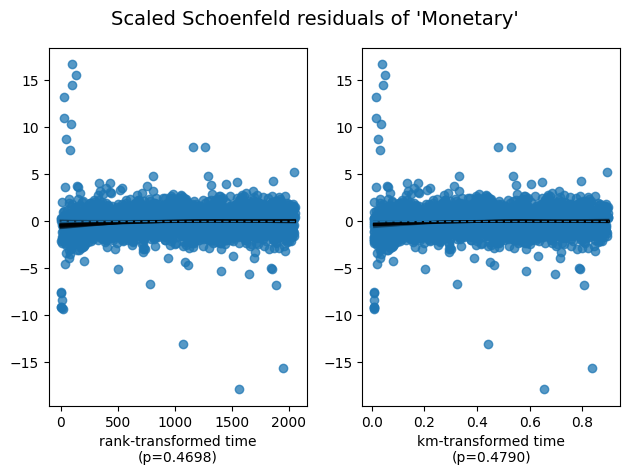

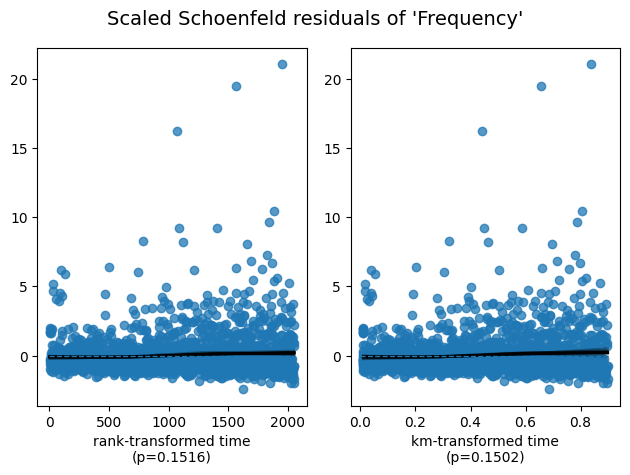

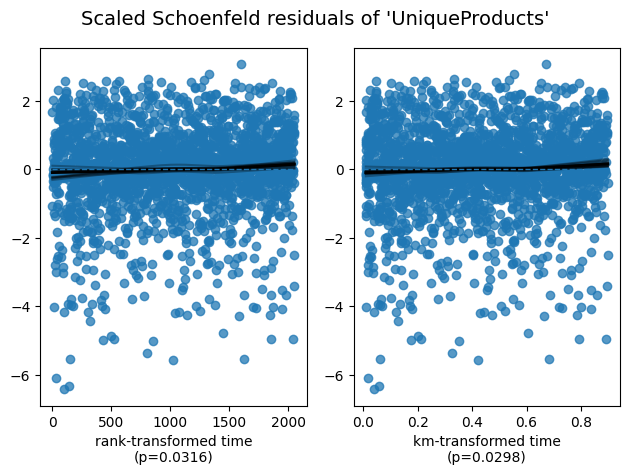

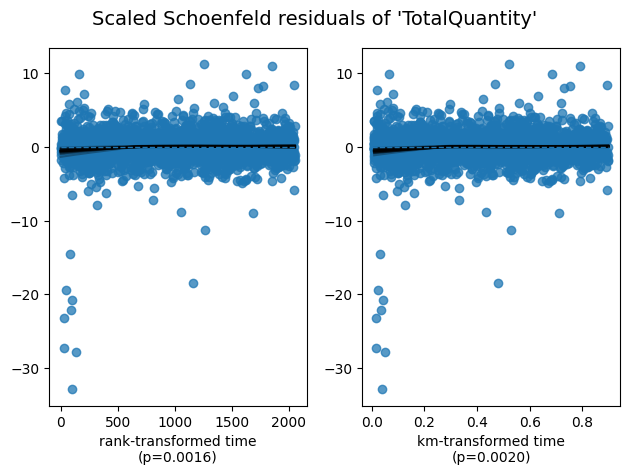

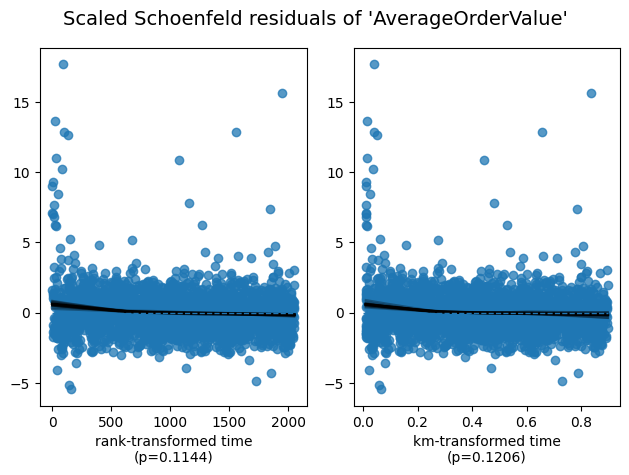

In [ ]:
cph.check_assumptions(
    cox_model_data,
    p_value_threshold=0.05,
    show_plots=True
)

In [ ]:
# Create a copy of the existing Cox model dataset
cox_nonlinear_data = cox_model_data.copy()

# Features showing possible PH violations
nonlinear_features = [
    'TotalQuantity',
    'UniqueProducts'
]

# Create centered quadratic terms
for col in nonlinear_features:

    squared_col = col + '_squared'

    cox_nonlinear_data[squared_col] = (
        cox_nonlinear_data[col] ** 2
    )

    cox_nonlinear_data[squared_col] -= (
        cox_nonlinear_data[squared_col].mean()
    )

print("New dataset shape:", cox_nonlinear_data.shape)

display(cox_nonlinear_data.head())

New dataset shape: (2491, 9)


,Duration,Event,Monetary,Frequency,UniqueProducts,TotalQuantity,AverageOrderValue,TotalQuantity_squared,UniqueProducts_squared
0,78.190278,1,-1.435733,2.941573,-1.739899,-2.068451,-3.527727,3.278487,2.027250
1,274.769444,1,0.896678,0.109233,0.783861,0.961286,1.000186,-0.075930,-0.385562
2,189.825000,1,0.353085,-0.696237,-0.618802,1.307109,0.897934,0.708535,-0.617084
3,18.859028,1,0.499728,-0.696237,0.245802,0.099747,1.079211,-0.990050,-0.939582
4,130.241667,1,-0.982841,-0.696237,-0.781274,-0.803542,-0.752087,-0.354320,-0.389611


In [ ]:
from lifelines import CoxPHFitter

cph_nonlinear = CoxPHFitter(penalizer=0.01)

cph_nonlinear.fit(
    cox_nonlinear_data,
    duration_col='Duration',
    event_col='Event',
    show_progress=True
)

cph_nonlinear.print_summary()

Iteration 1: norm_delta = 5.43e-01, step_size = 0.9500, log_lik = -14463.81662, newton_decrement = 2.73e+02, seconds_since_start = 0.1
Iteration 2: norm_delta = 2.65e-01, step_size = 0.9500, log_lik = -14210.04200, newton_decrement = 3.79e+01, seconds_since_start = 0.2
Iteration 3: norm_delta = 7.14e-02, step_size = 0.9500, log_lik = -14167.91587, newton_decrement = 3.78e+00, seconds_since_start = 0.2
Iteration 4: norm_delta = 1.14e-02, step_size = 1.0000, log_lik = -14163.77531, newton_decrement = 1.13e-01, seconds_since_start = 0.3
Iteration 5: norm_delta = 4.31e-04, step_size = 1.0000, log_lik = -14163.65941, newton_decrement = 1.48e-04, seconds_since_start = 0.4
Iteration 6: norm_delta = 5.75e-07, step_size = 1.0000, log_lik = -14163.65926, newton_decrement = 2.60e-10, seconds_since_start = 0.5
Convergence success after 6 iterations.


<lifelines.CoxPHFitter: fitted with 2491 total observations, 438 right-censored observations>
             duration col = 'Duration'
                event col = 'Event'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 2491
number of events observed = 2053
   partial log-likelihood = -14163.66
         time fit was run = 2026-11-26 19:54:23 UTC

---
                        coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                               
Monetary               -0.23      0.79      0.14           -0.52            0.05                0.60                1.05
Frequency              -0.40      0.67      0.08           -0.55           -0.24                0.58                0.79
UniqueProducts         -0.01      0.99      0.03           -0.07            0.05                0.93                1.05
TotalQuantity          -0.11      0.90      0.05           -0.20           -0.01                0.82                0.99
AverageOrderValue       0.08      1.08      0.12           -0.16            0.31                0.86                1.36
TotalQuantity_squared   0.04      1.05      0.01            0.02            0.07                1.02                1.07
UniqueProducts_squared -0.01      0.99      0.02           -0.04            0.03                0.96                1.03

                        cmp to     z      p  -log2(p)
covariate                                            
Monetary                  0.00 -1.62   0.11      3.24
Frequency                 0.00 -4.90 <0.005     20.03
UniqueProducts            0.00 -0.33   0.74      0.44
TotalQuantity             0.00 -2.26   0.02      5.40
AverageOrderValue         0.00  0.65   0.52      0.95
TotalQuantity_squared     0.00  3.51 <0.005     11.10
UniqueProducts_squared    0.00 -0.39   0.70      0.52
---
Concordance = 0.67
Partial AIC = 28341.32
log-likelihood ratio test = 600.31 on 7 df
-log2(p) of ll-ratio test = 414.18


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'TotalQuantity_squared' failed the non-proportional test: p-value is 0.0250.

   Advice 1: the functional form of the variable 'TotalQuantity_squared' might be incorrect. That
is, there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'TotalQuantity_squared' using pd.cut, and then specify it in
`strata=['TotalQuantity_squared', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it


[[<Axes: xlabel='rank-transformed time\n(p=0.3522)'>,
  <Axes: xlabel='km-transformed time\n(p=0.3622)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0907)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0935)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0958)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0827)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1749)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1837)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1606)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1657)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0250)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0310)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.6283)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5843)'>]]

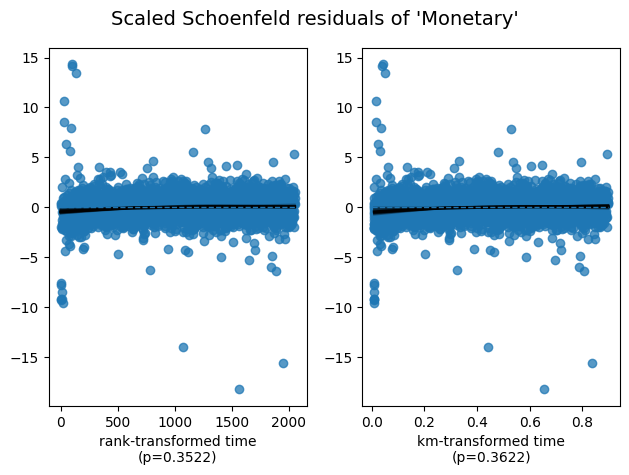

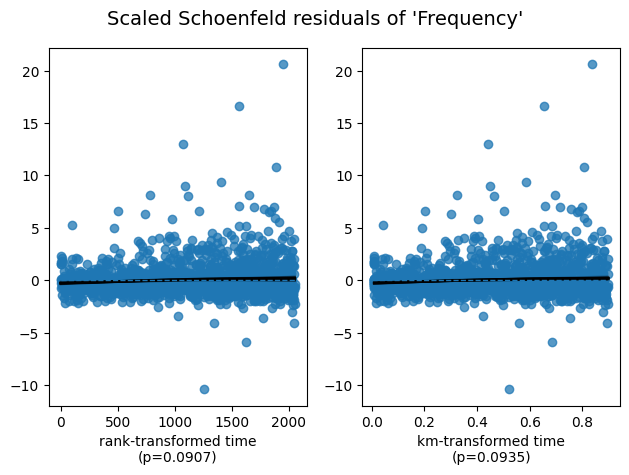

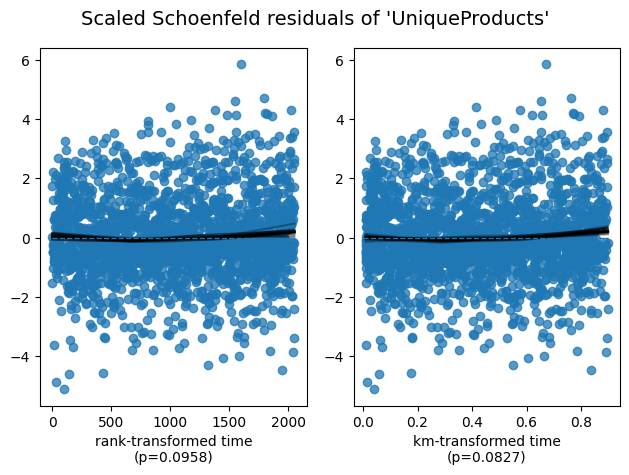

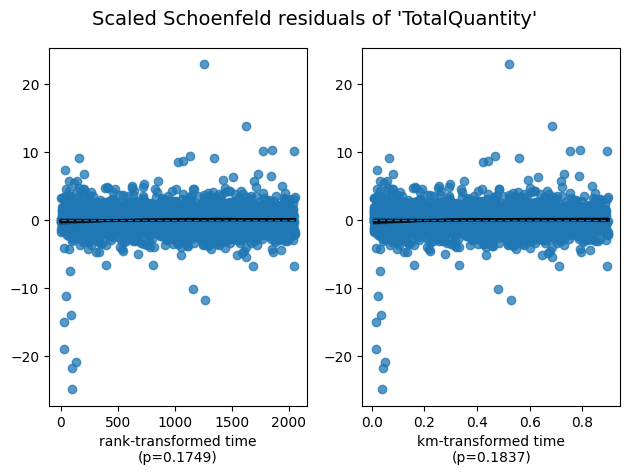

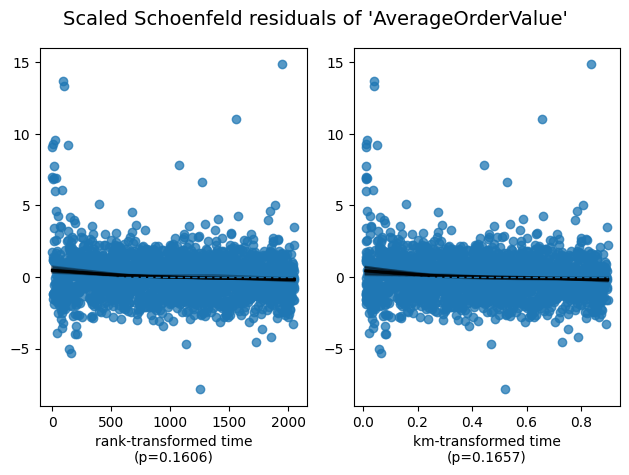

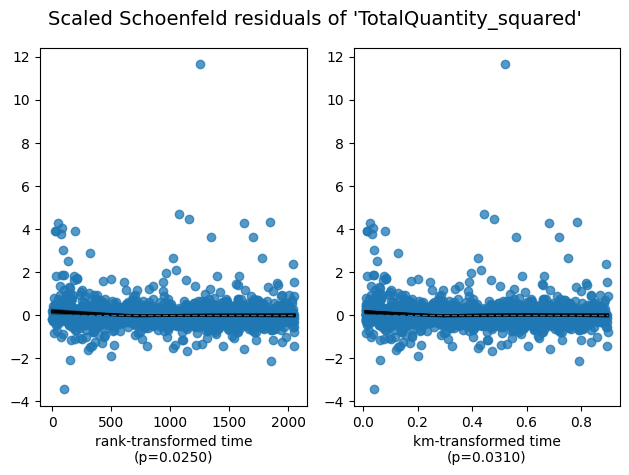

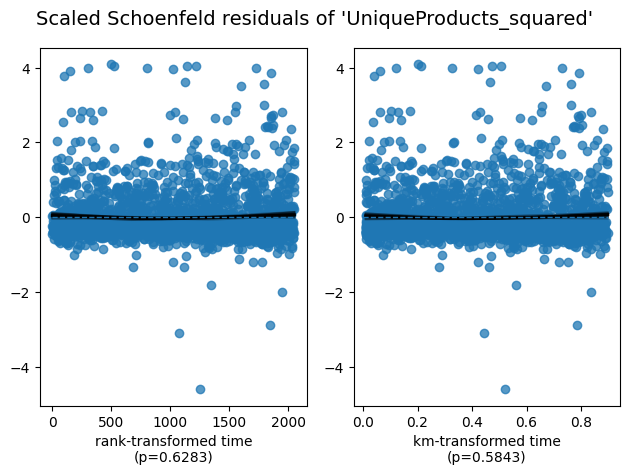

In [ ]:
cph_nonlinear.check_assumptions(
    cox_nonlinear_data,
    p_value_threshold=0.05,
    show_plots=True
)

In [ ]:
cph_nonlinear.summary[
    [
        'coef',
        'exp(coef)',
        'p',
        'exp(coef) lower 95%',
        'exp(coef) upper 95%'
    ]
]

,coef,exp(coef),p,exp(coef) lower 95%,exp(coef) upper 95%
covariate,,,,,
Monetary,-0.233486,0.791769,1.056988e-01,0.596695,1.050616
Frequency,-0.395208,0.673540,9.357808e-07,0.575143,0.788772
UniqueProducts,-0.010083,0.989968,7.380233e-01,0.933171,1.050221
TotalQuantity,-0.105593,0.899791,2.361004e-02,0.821167,0.985943
AverageOrderValue,0.076361,1.079352,5.182599e-01,0.856152,1.360741
TotalQuantity_squared,0.044602,1.045612,4.559821e-04,1.019858,1.072015
UniqueProducts_squared,-0.006156,0.993862,6.994689e-01,0.963277,1.025418


In [ ]:
print("Original C-index:", cph.concordance_index_)
print("Nonlinear C-index:", cph_nonlinear.concordance_index_)

print("Original AIC:", cph.AIC_partial_)
print("Nonlinear AIC:", cph_nonlinear.AIC_partial_)

Original C-index: 0.6733362159188565
Nonlinear C-index: 0.6740883043232663
Original AIC: 28348.414232961954
Nonlinear AIC: 28341.318513243776


In [ ]:
from lifelines import CoxTimeVaryingFitter

print("Cox time-varying model is ready.")

print("Dataset shape:", cox_dataset.shape)

display(
    cox_dataset[
        ['CustomerID', 'Duration', 'Event',
         'TotalQuantity', 'UniqueProducts']
    ].head()
)

Cox time-varying model is ready.
Dataset shape: (2491, 9)


,CustomerID,Duration,Event,TotalQuantity,UniqueProducts
0,12346.0,78.190278,1,51,7
1,12347.0,274.769444,1,1143,77
2,12348.0,189.825000,1,1627,21
3,12349.0,18.859028,1,474,47
4,12352.0,130.241667,1,188,18


In [ ]:
import numpy as np
import pandas as pd

# Prepare baseline features
tv_base = cox_model_data.reset_index(drop=True).copy()

# Preserve customer identifiers
tv_base['CustomerID'] = (
    cox_dataset.reset_index(drop=True)['CustomerID']
)

# Interval length in days
interval_length = 30

# Features used in the time-varying model
model_features = [
    'Monetary',
    'Frequency',
    'UniqueProducts',
    'TotalQuantity',
    'AverageOrderValue'
]

# Create start-stop intervals
tv_rows = []

for _, customer in tv_base.iterrows():

    duration = customer['Duration']
    event = int(customer['Event'])

    start = 0.0

    while start < duration:

        stop = min(start + interval_length, duration)

        # Event occurs only in the final interval
        interval_event = int(
            event == 1 and np.isclose(stop, duration)
        )

        midpoint = (start + stop) / 2

        row = {
            'CustomerID': customer['CustomerID'],
            'start': start,
            'stop': stop,
            'Event': interval_event
        }

        # Retain original standardized features
        for feature in model_features:
            row[feature] = customer[feature]

        # Time-varying interaction terms
        row['TotalQuantity_time'] = (
            customer['TotalQuantity'] * np.log1p(midpoint)
        )

        row['UniqueProducts_time'] = (
            customer['UniqueProducts'] * np.log1p(midpoint)
        )

        tv_rows.append(row)

        start = stop

# Construct final long-format dataset
tv_dataset = pd.DataFrame(tv_rows)

print("Time-varying dataset shape:", tv_dataset.shape)

print("\nNumber of unique customers:",
      tv_dataset['CustomerID'].nunique())

print("\nEvent distribution:")
print(tv_dataset['Event'].value_counts())

print("\nFirst 10 rows:")
display(tv_dataset.head(10))

Time-varying dataset shape: (13850, 11)

Number of unique customers: 2491

Event distribution:
Event
0    11796
1     2054
Name: count, dtype: int64

First 10 rows:


,CustomerID,start,stop,Event,Monetary,Frequency,UniqueProducts,TotalQuantity,AverageOrderValue,TotalQuantity_time,UniqueProducts_time
0,12346.0,0.0,30.000000,0,-1.435733,2.941573,-1.739899,-2.068451,-3.527727,-5.734963,-4.824026
1,12346.0,30.0,60.000000,0,-1.435733,2.941573,-1.739899,-2.068451,-3.527727,-7.919355,-6.661451
2,12346.0,60.0,78.190278,1,-1.435733,2.941573,-1.739899,-2.068451,-3.527727,-8.790612,-7.394318
3,12347.0,0.0,30.000000,0,0.896678,0.109233,0.783861,0.961286,1.000186,2.665250,2.173325
4,12347.0,30.0,60.000000,0,0.896678,0.109233,0.783861,0.961286,1.000186,3.680418,3.001124
5,12347.0,60.0,90.000000,0,0.896678,0.109233,0.783861,0.961286,1.000186,4.163072,3.394694
6,12347.0,90.0,120.000000,0,0.896678,0.109233,0.783861,0.961286,1.000186,4.482898,3.655489
7,12347.0,120.0,150.000000,0,0.896678,0.109233,0.783861,0.961286,1.000186,4.722465,3.850840
8,12347.0,150.0,180.000000,0,0.896678,0.109233,0.783861,0.961286,1.000186,4.914081,4.007089
9,12347.0,180.0,210.000000,0,0.896678,0.109233,0.783861,0.961286,1.000186,5.073776,4.137310


In [ ]:
# Check interval validity
print(
    "Invalid intervals:",
    (tv_dataset['stop'] <= tv_dataset['start']).sum()
)

# Check missing values
print(
    "\nMissing values:",
    tv_dataset.isnull().sum().sum()
)

# Check event count
print(
    "\nOriginal number of events:",
    cox_dataset['Event'].sum()
)

print(
    "Time-varying number of events:",
    tv_dataset['Event'].sum()
)

# Check whether each customer has exactly one final event
event_counts = tv_dataset.groupby('CustomerID')['Event'].sum()

print(
    "\nCustomers with more than one event:",
    (event_counts > 1).sum()
)

print(
    "Customers with no event:",
    (event_counts == 0).sum()
)

Invalid intervals: 0

Missing values: 0

Original number of events: 2053
Time-varying number of events: 2054

Customers with more than one event: 1
Customers with no event: 438


In [ ]:

# Rebuild time-varying dataset with corrected event assignment

tv_rows = []

for _, customer in tv_base.iterrows():

    duration = float(customer['Duration'])
    event = int(customer['Event'])

    start = 0.0

    while start < duration:

        stop = min(start + interval_length, duration)

        # Event can occur only in the final interval
        is_final_interval = (stop >= duration)

        interval_event = int(
            event == 1 and is_final_interval
        )

        midpoint = (start + stop) / 2

        row = {
            'CustomerID': customer['CustomerID'],
            'start': start,
            'stop': stop,
            'Event': interval_event
        }

        for feature in model_features:
            row[feature] = customer[feature]

        # Time-dependent interactions
        row['TotalQuantity_time'] = (
            customer['TotalQuantity'] * np.log1p(midpoint)
        )

        row['UniqueProducts_time'] = (
            customer['UniqueProducts'] * np.log1p(midpoint)
        )

        tv_rows.append(row)

        start = stop

tv_dataset = pd.DataFrame(tv_rows)

print("Updated dataset shape:", tv_dataset.shape)


Updated dataset shape: (13850, 11)


In [ ]:
print("Unique customers:",
      tv_dataset['CustomerID'].nunique())

print("Invalid intervals:",
      (tv_dataset['stop'] <= tv_dataset['start']).sum())

print("Missing values:",
      tv_dataset.isnull().sum().sum())

print("Original events:",
      cox_dataset['Event'].sum())

print("Time-varying events:",
      tv_dataset['Event'].sum())

event_counts = (
    tv_dataset.groupby('CustomerID')['Event'].sum()
)

print("Customers with multiple events:",
      (event_counts > 1).sum())

print("Customers with no event:",
      (event_counts == 0).sum())

print("Customers with exactly one event:",
      (event_counts == 1).sum())

Unique customers: 2491
Invalid intervals: 0
Missing values: 0
Original events: 2053
Time-varying events: 2053
Customers with multiple events: 0
Customers with no event: 438
Customers with exactly one event: 2053


In [ ]:

from lifelines import CoxTimeVaryingFitter

# Select features for the time-varying Cox model
tv_features = [
    'Monetary',
    'Frequency',
    'UniqueProducts',
    'TotalQuantity',
    'AverageOrderValue',
    'TotalQuantity_time',
    'UniqueProducts_time'
]

# Prepare model dataset
tv_model_data = tv_dataset[
    ['CustomerID', 'start', 'stop', 'Event'] + tv_features
].copy()

# Initialize model
ctv = CoxTimeVaryingFitter(penalizer=0.01)

# Fit model
ctv.fit(
    tv_model_data,
    id_col='CustomerID',
    start_col='start',
    stop_col='stop',
    event_col='Event',
    show_progress=True
)

# Display results
ctv.print_summary()


Iteration 1: norm_delta = 6.78e-01, step_size = 0.9500, log_lik = -14463.81662, newton_decrement = 2.58e+02, seconds_since_start = 3.5
Iteration 2: norm_delta = 1.83e-01, step_size = 0.9500, log_lik = -14179.92336, newton_decrement = 2.33e+01, seconds_since_start = 5.9
Iteration 3: norm_delta = 2.80e-02, step_size = 0.9500, log_lik = -14155.42412, newton_decrement = 4.91e-01, seconds_since_start = 7.8
Iteration 4: norm_delta = 1.89e-03, step_size = 1.0000, log_lik = -14154.93052, newton_decrement = 1.98e-03, seconds_since_start = 8.7
Iteration 5: norm_delta = 1.69e-06, step_size = 1.0000, log_lik = -14154.92854, newton_decrement = 1.65e-09, seconds_since_start = 9.6
Convergence completed after 5 iterations.


<lifelines.CoxTimeVaryingFitter: fitted with 13850 periods, 2491 subjects, 2053 events>
         event col = 'Event'
         penalizer = 0.01
number of subjects = 2491
 number of periods = 13850
  number of events = 2053
partial log-likelihood = -14154.93
  time fit was run = 2026-11-26 20:01:48 UTC

---
                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                            
Monetary            -0.24      0.79      0.06           -0.36           -0.12                0.70                0.89
Frequency           -0.35      0.71      0.04           -0.42           -0.27                0.66                0.76
UniqueProducts      -0.25      0.78      0.05           -0.35           -0.15                0.70                0.86
TotalQuantity       -0.33      0.72      0.05           -0.44           -0.23                0.65                0.79
AverageOrderValue    0.05      1.06      0.05           -0.05            0.16                0.95                1.17
TotalQuantity_time   0.06      1.06      0.01            0.04            0.08                1.04                1.09
UniqueProducts_time  0.06      1.06      0.01            0.03            0.08                1.03                1.08

                     cmp to     z      p  -log2(p)
covariate                                         
Monetary               0.00 -3.96 <0.005     13.69
Frequency              0.00 -9.21 <0.005     64.72
UniqueProducts         0.00 -5.04 <0.005     21.07
TotalQuantity          0.00 -6.50 <0.005     33.56
AverageOrderValue      0.00  1.05   0.29      1.77
TotalQuantity_time     0.00  5.38 <0.005     23.64
UniqueProducts_time    0.00  4.89 <0.005     19.95
---
Partial AIC = 28323.86
log-likelihood ratio test = 617.78 on 7 df
-log2(p) of ll-ratio test = 426.67

In [ ]:

# Calculate time-specific hazard ratios

import numpy as np
import pandas as pd

# Extract fitted coefficients
params = ctv.params_

# Follow-up times in days
time_points = [0, 30, 90, 180, 365, 540]

results = []

for t in time_points:

    log_time = np.log1p(t)

    # Effective coefficient at time t
    tq_beta = (
        params['TotalQuantity']
        + params['TotalQuantity_time'] * log_time
    )

    up_beta = (
        params['UniqueProducts']
        + params['UniqueProducts_time'] * log_time
    )

    results.append({
        'FollowUp_Days': t,
        'TotalQuantity_HR': np.exp(tq_beta),
        'UniqueProducts_HR': np.exp(up_beta)
    })

time_hr_df = pd.DataFrame(results)

display(
    time_hr_df.round(4)
)


,FollowUp_Days,TotalQuantity_HR,UniqueProducts_HR
0,0,0.7159,0.7767
1,30,0.8858,0.9426
2,90,0.9470,1.0016
3,180,0.9883,1.0412
4,365,1.0324,1.0834
5,540,1.0578,1.1075


In [ ]:
# Time-specific hazard ratios with 95% confidence intervals

import numpy as np
import pandas as pd

params = ctv.params_
# Ensure both index and columns are labeled with feature names
cov_matrix = pd.DataFrame(
    ctv.variance_matrix_.values,
    index=ctv.params_.index,
    columns=ctv.params_.index
)

time_points = [0, 30, 90, 180, 365, 540]

results = []

features = {
    'TotalQuantity': 'TotalQuantity_time',
    'UniqueProducts': 'UniqueProducts_time'
}

for t in time_points:

    log_time = np.log1p(t)

    row = {'FollowUp_Days': t}

    for feature, interaction in features.items():

        beta = params[feature]
        gamma = params[interaction]

        # Effective coefficient at time t
        effective_beta = beta + gamma * log_time

        # Variance using the delta method
        variance = (
            cov_matrix.loc[feature, feature]
            + (log_time ** 2) *
              cov_matrix.loc[interaction, interaction]
            + 2 * log_time *
              cov_matrix.loc[feature, interaction]
        )

        se = np.sqrt(max(variance, 0))

        # Hazard ratio and confidence intervals
        hr = np.exp(effective_beta)
        lower = np.exp(effective_beta - 1.96 * se)
        upper = np.exp(effective_beta + 1.96 * se)

        row[f'{feature}_HR'] = hr
        row[f'{feature}_Lower95'] = lower
        row[f'{feature}_Upper95'] = upper

    results.append(row)

time_hr_ci_df = pd.DataFrame(results)

display(time_hr_ci_df.round(4))

,FollowUp_Days,TotalQuantity_HR,TotalQuantity_Lower95,TotalQuantity_Upper95,UniqueProducts_HR,UniqueProducts_Lower95,UniqueProducts_Upper95
0,0,0.7159,0.6473,0.7918,0.7767,0.7041,0.8568
1,30,0.8858,0.8192,0.9579,0.9426,0.8957,0.9920
2,90,0.9470,0.8693,1.0317,1.0016,0.9493,1.0568
3,180,0.9883,0.9001,1.0852,1.0412,0.9800,1.1062
4,365,1.0324,0.9311,1.1448,1.0834,1.0096,1.1626
5,540,1.0578,0.9482,1.1801,1.1075,1.0255,1.1961


In [ ]:

# STEP 7.1: Compare survival models

import pandas as pd

model_comparison = pd.DataFrame({
    'Model': [
        'Standard Cox PH',
        'Nonlinear Cox PH',
        'Time-Varying Cox'
    ],
    'Partial Log-Likelihood': [
        cph.log_likelihood_,
        cph_nonlinear.log_likelihood_,
        ctv.log_likelihood_
    ],
    'Partial AIC': [
        cph.AIC_partial_,
        cph_nonlinear.AIC_partial_,
        ctv.AIC_partial_
    ],
    'Number of Parameters': [
        len(cph.params_),
        len(cph_nonlinear.params_),
        len(ctv.params_)
    ]
})

display(model_comparison.round(4))


,Model,Partial Log-Likelihood,Partial AIC,Number of Parameters
0,Standard Cox PH,-14169.2071,28348.4142,5
1,Nonlinear Cox PH,-14163.6593,28341.3185,7
2,Time-Varying Cox,-14154.9285,28323.8571,7


In [ ]:

# STEP 7.2: Sensitivity analysis for interval length

def create_tv_dataset(interval_days):

    rows = []

    for _, row in tv_base.iterrows():

        duration = row['Duration']
        event = row['Event']

        start = 0

        while start < duration:

            stop = min(start + interval_days, duration)

            midpoint = (start + stop) / 2

            new_row = {
                'CustomerID': row['CustomerID'],
                'start': start,
                'stop': stop,

                'Event': int(
                    event == 1 and stop >= duration
                ),

                'Monetary': row['Monetary'],
                'Frequency': row['Frequency'],
                'UniqueProducts': row['UniqueProducts'],
                'TotalQuantity': row['TotalQuantity'],
                'AverageOrderValue': row['AverageOrderValue'],

                'TotalQuantity_time':
                    row['TotalQuantity'] * np.log1p(midpoint),

                'UniqueProducts_time':
                    row['UniqueProducts'] * np.log1p(midpoint)
            }

            rows.append(new_row)

            start = stop

    return pd.DataFrame(rows)


# Generate datasets with different interval lengths

tv_15 = create_tv_dataset(15)
tv_30 = create_tv_dataset(30)
tv_60 = create_tv_dataset(60)

print("15-day dataset:", tv_15.shape)
print("30-day dataset:", tv_30.shape)
print("60-day dataset:", tv_60.shape)


15-day dataset: (26334, 11)
30-day dataset: (13850, 11)
60-day dataset: (7599, 11)


In [ ]:

# STEP 7.3: Validate interval datasets

datasets = {
    '15-day': tv_15,
    '30-day': tv_30,
    '60-day': tv_60
}

for name, df in datasets.items():

    print(f"\n{'='*45}")
    print(f"{name} DATASET")
    print(f"{'='*45}")

    print("Total intervals:", len(df))

    print("Unique customers:",
          df['CustomerID'].nunique())

    print("Total events:",
          df['Event'].sum())

    print("Customers with multiple events:",
          (df.groupby('CustomerID')['Event'].sum() > 1).sum())

    print("Customers with no event:",
          (df.groupby('CustomerID')['Event'].sum() == 0).sum())

    print("Missing values:", df.isnull().sum().sum())

    invalid_intervals = (
        (df['start'] < 0) |
        (df['stop'] <= df['start'])
    ).sum()

    print("Invalid intervals:", invalid_intervals)

    print("Total event records per customer:")
    print(df.groupby('CustomerID')['Event'].sum().value_counts().sort_index())



15-day DATASET
Total intervals: 26334
Unique customers: 2491
Total events: 2053
Customers with multiple events: 0
Customers with no event: 438
Missing values: 0
Invalid intervals: 0
Total event records per customer:
Event
0     438
1    2053
Name: count, dtype: int64

30-day DATASET
Total intervals: 13850
Unique customers: 2491
Total events: 2053
Customers with multiple events: 0
Customers with no event: 438
Missing values: 0
Invalid intervals: 0
Total event records per customer:
Event
0     438
1    2053
Name: count, dtype: int64

60-day DATASET
Total intervals: 7599
Unique customers: 2491
Total events: 2053
Customers with multiple events: 0
Customers with no event: 438
Missing values: 0
Invalid intervals: 0
Total event records per customer:
Event
0     438
1    2053
Name: count, dtype: int64


In [ ]:

# STEP 7.4: Fit time-varying Cox models

from lifelines import CoxTimeVaryingFitter
import pandas as pd
import numpy as np

datasets = {
    '15-day': tv_15,
    '30-day': tv_30,
    '60-day': tv_60
}

tv_models = {}
sensitivity_results = []

tv_features = [
    'Monetary',
    'Frequency',
    'UniqueProducts',
    'TotalQuantity',
    'AverageOrderValue',
    'TotalQuantity_time',
    'UniqueProducts_time'
]

for name, df in datasets.items():

    print(f"\nFitting {name} model...")

    model_data = df[
        ['CustomerID', 'start', 'stop', 'Event'] + tv_features
    ].copy()

    model = CoxTimeVaryingFitter(penalizer=0.01)

    model.fit(
        model_data,
        id_col='CustomerID',
        start_col='start',
        stop_col='stop',
        event_col='Event',
        show_progress=True
    )

    tv_models[name] = model

    sensitivity_results.append({
        'Interval': name,
        'Partial Log-Likelihood': model.log_likelihood_,
        'Partial AIC': model.AIC_partial_,
        'Parameters': len(model.params_)
    })

    print(f"{name} model completed.")

# Display comparison

sensitivity_comparison = pd.DataFrame(sensitivity_results)

display(sensitivity_comparison.round(4))



Fitting 15-day model...
Iteration 1: norm_delta = 4.48e-01, step_size = 0.9500, log_lik = -14463.81662, newton_decrement = 2.31e+02, seconds_since_start = 5.6
Iteration 2: norm_delta = 1.47e-01, step_size = 0.9500, log_lik = -14208.46017, newton_decrement = 1.90e+01, seconds_since_start = 9.3
Iteration 3: norm_delta = 1.95e-02, step_size = 0.9500, log_lik = -14188.70777, newton_decrement = 2.99e-01, seconds_since_start = 11.8
Iteration 4: norm_delta = 1.22e-03, step_size = 1.0000, log_lik = -14188.40807, newton_decrement = 1.05e-03, seconds_since_start = 13.5
Iteration 5: norm_delta = 6.96e-07, step_size = 1.0000, log_lik = -14188.40702, newton_decrement = 3.41e-10, seconds_since_start = 15.2
Convergence completed after 5 iterations.
15-day model completed.

Fitting 30-day model...
Iteration 1: norm_delta = 6.78e-01, step_size = 0.9500, log_lik = -14463.81662, newton_decrement = 2.58e+02, seconds_since_start = 1.1
Iteration 2: norm_delta = 1.83e-01, step_size = 0.9500, log_lik = -1417

,Interval,Partial Log-Likelihood,Partial AIC,Parameters
0,15-day,-14188.4070,28390.8140,7
1,30-day,-14154.9285,28323.8571,7
2,60-day,-14119.5874,28253.1748,7


In [ ]:

# STEP 7.5: Compare coefficients and hazard ratios

coefficient_results = []

for interval, model in tv_models.items():

    for feature in tv_features:

        coefficient = model.params_[feature]

        coefficient_results.append({
            'Interval': interval,
            'Feature': feature,
            'Coefficient': coefficient,
            'Hazard_Ratio': np.exp(coefficient)
        })

coefficient_comparison = pd.DataFrame(coefficient_results)

display(
    coefficient_comparison.pivot(
        index='Feature',
        columns='Interval',
        values='Hazard_Ratio'
    ).round(4)
)


Interval,15-day,30-day,60-day
Feature,,,
AverageOrderValue,1.0513,1.0560,1.0506
Frequency,0.7420,0.7077,0.6806
Monetary,0.8154,0.7879,0.7633
TotalQuantity,0.7961,0.7159,0.6297
TotalQuantity_time,1.0292,1.0640,1.1077
UniqueProducts,0.8546,0.7767,0.6991
UniqueProducts_time,1.0315,1.0580,1.0868


In [ ]:

# STEP 7.6: Compare statistical significance across intervals

significance_results = []

for interval, model in tv_models.items():

    summary = model.summary

    for feature in tv_features:

        significance_results.append({
            'Interval': interval,
            'Feature': feature,
            'Coefficient': summary.loc[feature, 'coef'],
            'Hazard_Ratio': summary.loc[feature, 'exp(coef)'],
            'P_Value': summary.loc[feature, 'p'],
            'CI_Lower': summary.loc[feature, 'exp(coef) lower 95%'],
            'CI_Upper': summary.loc[feature, 'exp(coef) upper 95%']
        })

significance_comparison = pd.DataFrame(significance_results)

display(significance_comparison.round(4))


,Interval,Feature,Coefficient,Hazard_Ratio,P_Value,CI_Lower,CI_Upper
0,15-day,Monetary,-0.2040,0.8154,0.0000,0.7462,0.8911
1,15-day,Frequency,-0.2984,0.7420,0.0000,0.6996,0.7869
2,15-day,UniqueProducts,-0.1572,0.8546,0.0001,0.7907,0.9237
3,15-day,TotalQuantity,-0.2281,0.7961,0.0000,0.7330,0.8646
4,15-day,AverageOrderValue,0.0501,1.0513,0.2162,0.9712,1.1381
5,15-day,TotalQuantity_time,0.0288,1.0292,0.0016,1.0110,1.0478
6,15-day,UniqueProducts_time,0.0310,1.0315,0.0006,1.0133,1.0499
7,30-day,Monetary,-0.2384,0.7879,0.0001,0.7002,0.8866
8,30-day,Frequency,-0.3458,0.7077,0.0000,0.6575,0.7617
9,30-day,UniqueProducts,-0.2527,0.7767,0.0000,0.7041,0.8568


In [ ]:
# STEP 7.7: Effective coefficient confidence intervals

model = tv_models['30-day']

params = model.params_
# Ensure both index and columns are correctly labeled with feature names
cov = pd.DataFrame(
    model.variance_matrix_.values,
    index=model.params_.index,
    columns=model.params_.index
)

time_points = [0, 30, 90, 180, 365, 540]

features = {
    'TotalQuantity': 'TotalQuantity_time',
    'UniqueProducts': 'UniqueProducts_time'
}

results = []

for t in time_points:

    log_time = np.log1p(t)

    for feature, interaction in features.items():

        beta = params[feature]
        gamma = params[interaction]

        effective_beta = beta + gamma * log_time

        variance = (
            cov.loc[feature, feature]
            + log_time**2 * cov.loc[interaction, interaction]
            + 2 * log_time * cov.loc[feature, interaction]
        )

        se = np.sqrt(max(variance, 0))

        results.append({
            'FollowUp_Days': t,
            'Feature': feature,
            'Effective_Coefficient': effective_beta,
            'Hazard_Ratio': np.exp(effective_beta),
            'Lower95': np.exp(effective_beta - 1.96 * se),
            'Upper95': np.exp(effective_beta + 1.96 * se)
        })

effective_effects = pd.DataFrame(results)

display(effective_effects.round(4))

,FollowUp_Days,Feature,Effective_Coefficient,Hazard_Ratio,Lower95,Upper95
0,0,TotalQuantity,-0.3343,0.7159,0.6473,0.7918
1,0,UniqueProducts,-0.2527,0.7767,0.7041,0.8568
2,30,TotalQuantity,-0.1212,0.8858,0.8192,0.9579
3,30,UniqueProducts,-0.0591,0.9426,0.8957,0.9920
4,90,TotalQuantity,-0.0544,0.9470,0.8693,1.0317
5,90,UniqueProducts,0.0016,1.0016,0.9493,1.0568
6,180,TotalQuantity,-0.0118,0.9883,0.9001,1.0852
7,180,UniqueProducts,0.0404,1.0412,0.9800,1.1062
8,365,TotalQuantity,0.0319,1.0324,0.9311,1.1448
9,365,UniqueProducts,0.0801,1.0834,1.0096,1.1626


In [103]:

customer_survival.to_csv(
    'customer_survival_dataset.csv', index=False
)

cox_dataset.to_csv(
    'cox_dataset.csv', index=False
)

tv_30.to_csv(
    'tv_dataset_30day.csv', index=False
)

sensitivity_comparison.to_csv(
    'survival_interval_sensitivity.csv', index=False
)

effective_effects.to_csv(
    'survival_time_dependent_effects.csv', index=False
)

from google.colab import files

files.download('customer_survival_dataset.csv')
files.download('cox_dataset.csv')
files.download('tv_dataset_30day.csv')
files.download('survival_interval_sensitivity.csv')
files.download('survival_time_dependent_effects.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>